# 03 · Data Preparation — cleaning, missing values, outliers, encoding
**Phase 2 (Skill 2 – data preparation)** · NextDeal for BH Assurance

Every decision below comes from the audit of notebook 02 (`reports/data_quality_findings.csv`).

| Step | Dataset A – companies (PM) | Dataset B – expiring contracts (PP) |
|---|---|---|
| 1. Remove | leaky `score` / `Bought`, constant PII `email` | constant `decision`, broken `Age`, unreliable `nb_sinistres_2025` |
| 2. Normalise text | accents, case, double spaces, `NON DEFINI` → NaN | same + `Non classé` / `Non défini` → NaN |
| 3. Missing values | sector imputed from activity, else `UNKNOWN` | `UNKNOWN` category for text fields |
| 4. Outliers | `age_contract` binarised (`has_history`) | `Age_Contrat` kept (business-valid) + `log1p` |
| 5. Restructure | 1 row per company + multi-hot portfolio + **leave-one-out episodes** | dates → durations, guarantees → multi-hot |
| 6. Encode | one-hot (category, top sectors) + frequency (activity) + multi-hot | one-hot + multi-hot, binary target `unpaid` |

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (RAW, PROCESSED, ROOT, set_style, save, subtitle, PALETTE, INK, INK_2,
                       normalize_label, split_multi)

set_style()
pd.set_option("display.max_columns", 40)
BLUE, ORANGE, GREEN = PALETTE[0], PALETTE[1], PALETTE[2]


def audit(df: pd.DataFrame, name: str) -> dict:
    return {"dataset": name, "rows": len(df), "columns": df.shape[1],
            "missing cells": int(df.isna().sum().sum()),
            "missing %": round(float(df.isna().mean().mean() * 100), 2)}

## A. Corporate portfolio (PM)
### A1. Load and remove leaky / useless columns

In [2]:
pm_raw = pd.read_csv(RAW / "pm_product_portfolio.csv", sep=";", encoding="utf-8-sig")
log = [audit(pm_raw, "A · raw")]

pm = pm_raw.drop(columns=["score", "Bought", "email"])   # leakage (nb 02 §2.7) + constant PII
print("kept columns:", list(pm.columns))

kept columns: ['REF_pm', 'LIB_SECTEUR_ACTIVITE', 'LIB_ACTIVITE', 'LIB_PRODUIT', 'BRANCHE', 'LIB_SOUS_BRANCHE', 'age_contract', 'category', 'candidate_product']


### A2. Normalise text and reveal hidden missing values

In [3]:
TEXT_PM = ["LIB_SECTEUR_ACTIVITE", "LIB_ACTIVITE", "LIB_PRODUIT", "BRANCHE", "LIB_SOUS_BRANCHE",
           "category", "candidate_product"]
before = pm[TEXT_PM].isna().sum()
for c in TEXT_PM:
    pm[c] = pm[c].map(normalize_label)
after = pm[TEXT_PM].isna().sum()
pd.DataFrame({"NaN before": before, "NaN after normalisation": after}).query("`NaN after normalisation` > 0")

,NaN before,NaN after normalisation
LIB_SECTEUR_ACTIVITE,170,170
LIB_ACTIVITE,8,161


### A3. One row per company
The raw table repeats the company profile for every (held product × candidate) pair.
The analytical unit for cross-selling is the **company and its portfolio**.

In [4]:
profile_cols = ["LIB_SECTEUR_ACTIVITE", "LIB_ACTIVITE", "category"]
assert (pm.groupby("REF_pm")[profile_cols].nunique(dropna=False) <= 1).all().all(), "profile not constant per company"

companies = pm.groupby("REF_pm").agg(
    sector=("LIB_SECTEUR_ACTIVITE", "first"),
    activity=("LIB_ACTIVITE", "first"),
    category=("category", "first"),
    portfolio=("LIB_PRODUIT", lambda s: sorted(set(s))),
    branches=("BRANCHE", lambda s: sorted(set(s))),
    max_contract_age=("age_contract", "max"),
).reset_index()
companies["n_products"] = companies["portfolio"].str.len()
companies["n_branches"] = companies["branches"].str.len()
print(companies.shape)
companies.head()

(299, 9)


,REF_pm,sector,activity,category,portfolio,branches,max_contract_age,n_products,n_branches
0,6958,COMMERCE ET REPARATION AUTOMOBILE,COMMERCE DE GROS D EQUIPEMENTS AUTOMOBILES,COMMERCE & SERVICES,[AUTOMOBILE],[AUTOMOBILE],0.0,1,1
1,12068,SERVICES PERSONNELS,AUTRES SERVICES PERSONNELS,COMMERCE & SERVICES,[AUTOMOBILE II],[AUTOMOBILE],0.0,1,1
2,12112,INTERMEDIATION FINANCIERE,CREDIT BAIL,FINANCE & ASSURANCE,"[AUTOMOBILE, AUTOMOBILE II, AUTOMOBILE LEASING...","[AUTOMOBILE, ENGINEERING, INCENDIE, RISQUES DI...",0.0,7,4
3,12145,TRAVAIL DU BOIS ET FABRICATION D ARTICLES EN BOIS,FABRICATION D EMBALLAGES EN BOIS,INDUSTRIES & MANUFACTURING,[AUTOMOBILE],[AUTOMOBILE],0.0,1,1
4,12169,INTERMEDIATION FINANCIERE,CREDIT BAIL,FINANCE & ASSURANCE,[RC ENTREPRISE DE BATIMENT ET TRAVAUX PUBLIC],[RISQUES DIVERS],0.0,1,1


### A4. Missing values — sector imputed from activity
Strategy (business rules first, statistics second):
1. a missing sector takes the **most frequent sector of companies with the same activity**;
2. activities never seen with a sector are mapped by a **domain rule** validated with the business
   (`CLINIQUE → SANTE ET ACTION SOCIALE`, `INSTITUT DE FORMATION → EDUCATION`);
3. the category of an imputed company is re-derived from its new sector;
4. whatever is still unknown becomes the explicit level `UNKNOWN`, so the model can learn whether
   "unknown" itself carries signal (52 companies have neither sector nor activity).

In [5]:
miss_before = companies[["sector", "activity", "category"]].isna().sum()
DOMAIN_RULES = {"CLINIQUE": "SANTE ET ACTION SOCIALE", "INSTITUT DE FORMATION": "EDUCATION"}

activity_to_sector = (companies.dropna(subset=["sector", "activity"])
                      .groupby("activity")["sector"].agg(lambda s: s.mode().iat[0]))
by_activity = companies["sector"].isna() & companies["activity"].map(activity_to_sector).notna()
companies.loc[by_activity, "sector"] = companies.loc[by_activity, "activity"].map(activity_to_sector)
by_rule = companies["sector"].isna() & companies["activity"].isin(DOMAIN_RULES)
companies.loc[by_rule, "sector"] = companies.loc[by_rule, "activity"].map(DOMAIN_RULES)
imputed = by_activity | by_rule
companies["sector_imputed"] = imputed.astype(int)

sector_to_category = (companies.loc[~imputed].dropna(subset=["sector"])
                      .groupby("sector")["category"].agg(lambda s: s.mode().iat[0]))
companies.loc[imputed, "category"] = companies.loc[imputed, "sector"].map(sector_to_category).fillna(
    companies.loc[imputed, "category"])

for c in ["sector", "activity", "category"]:
    companies[c] = companies[c].fillna("UNKNOWN")
pd.DataFrame({"missing before": miss_before,
              "imputed (same activity)": [int(by_activity.sum()), 0, 0],
              "imputed (domain rule)": [int(by_rule.sum()), 0, 0],
              "still UNKNOWN": companies[["sector", "activity", "category"]].eq("UNKNOWN").sum()})

,missing before,imputed (same activity),imputed (domain rule),still UNKNOWN
sector,57,0,5,52
activity,53,0,0,53
category,0,0,0,0


### A5. Outliers — contract age
`age_contract` is 0 for 90 % of contracts, so the IQR fence is 0 and *every* non-zero value is a
statistical outlier. Clipping would erase all information; instead we keep the business meaning:
**has the company held a contract for more than a year?**

In [6]:
companies["has_history"] = (companies["max_contract_age"] > 0).astype(int)
companies["max_contract_age"] = companies["max_contract_age"].clip(upper=10)
companies[["max_contract_age", "has_history"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
max_contract_age,299.0,0.52,1.89,0.0,0.0,0.0,0.0,10.0
has_history,299.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0


### A6. Multi-hot portfolio and product catalogue

The catalogue contains 46 products, but only 34 are held in this extract. The 12 candidate-only products have no positive training examples and no branch mapping in the exported catalogue. The v1 classifier cannot learn their purchase propensity from this data.

In [7]:
PRODUCTS = sorted(set(pm["LIB_PRODUIT"]) | set(pm["candidate_product"]))
product_branch = (pm[["LIB_PRODUIT", "BRANCHE"]].drop_duplicates().set_index("LIB_PRODUIT")["BRANCHE"].to_dict())
print(f"{len(PRODUCTS)} products in the catalogue, {pm['LIB_PRODUIT'].nunique()} actually held")

portfolio_mh = pd.DataFrame(0, index=companies["REF_pm"], columns=PRODUCTS, dtype=int)
for ref, prods in zip(companies["REF_pm"], companies["portfolio"]):
    portfolio_mh.loc[ref, prods] = 1
print("multi-hot shape:", portfolio_mh.shape, "· density:", round(portfolio_mh.values.mean(), 3))
portfolio_mh.sum().sort_values(ascending=False).head(8).to_frame("companies holding")

46 products in the catalogue, 34 actually held
multi-hot shape: (299, 46) · density: 0.032


,companies holding
AUTOMOBILE,130
AUTOMOBILE II,78
MULTIRISQUES PROFESSIONNELLES CENTRALISE,61
SANTE ET PREVOYANCE,45
POLICE ABONNEMENT(FACULTE MARITIME),25
OMNICANAL AUTOMOBILE PACK2,16
OMNICANAL AUTOMOBILE PACK PERSONALISE,16
RESPONSABILITE CIVILE,12


### A7. Leave-one-out episodes — the honest modeling target
For a company holding products {A, B, C} we create three **episodes**: hide A and keep {B, C}
as known, hide B and keep {A, C}, hide C and keep {A, B}. The model must recover the hidden
product from the profile and the visible portfolio — an offline portfolio-reconstruction proxy for recommendation quality. It does not establish the order of purchases, future conversion or causal uplift. Mono-product companies give one "cold-start" episode
(empty visible portfolio, profile only).

In [8]:
episodes = []
for row in companies.itertuples():
    for hidden in row.portfolio:
        visible = [p for p in row.portfolio if p != hidden]
        episodes.append({"REF_pm": row.REF_pm, "hidden_product": hidden,
                         "visible_portfolio": ";".join(visible), "n_visible": len(visible)})
episodes = pd.DataFrame(episodes).merge(
    companies[["REF_pm", "sector", "activity", "category", "sector_imputed", "has_history", "max_contract_age"]],
    on="REF_pm")
print(f"{len(episodes)} episodes from {episodes['REF_pm'].nunique()} companies · "
      f"cold-start episodes: {(episodes['n_visible'] == 0).mean():.0%}")
episodes.sample(5, random_state=1)

440 episodes from 299 companies · cold-start episodes: 47%


,REF_pm,hidden_product,visible_portfolio,n_visible,sector,activity,category,sector_imputed,has_history,max_contract_age
283,557149,AUTOMOBILE II,OMNICANAL AUTOMOBILE PACK2,1,UNKNOWN,UNKNOWN,OTHER,0,0,0.0
369,575944,AUTOMOBILE,,0,"AGRICULTURE, CHASSE, SERVICES ANNEXES",CULTURE DE CEREALES ; CULTURES INDUSTRIELLES,OTHER,0,1,1.0
207,435481,MULTIRISQUES PROFESSIONNELLES CENTRALISE,,0,EDUCATION,INSTITUT DE FORMATION,PUBLIC & SOCIAL ACTIVITIES,1,0,0.0
300,559316,AUTOMOBILE II,AUTOMOBILE;OMNICANAL AUTOMOBILE PACK PERSONALISE,2,UNKNOWN,UNKNOWN,OTHER,0,0,0.0
429,593001,OMNICANAL AUTOMOBILE PACK PERSONALISE,,0,AGENCES ET BUREAUX,AGENCES ET BUREAUX,PUBLIC & SOCIAL ACTIVITIES,0,0,0.0


### A8. Encoding pipeline
- **One-hot** for `category` (8 levels) and `sector` (rare levels < 5 companies grouped by `min_frequency`).
- **Frequency encoding** for `activity` (141 levels – one-hot would create 141 sparse columns for 299 companies).
- **Multi-hot** for the visible portfolio (46 product columns).
- Numerical: `n_visible`, `has_history`, `max_contract_age`, `sector_imputed`.

The pipeline lives in `src/features.py`. Its encoders (including the frequency map) are **fitted
inside each cross-validation fold** in notebook 04. However, the learned activity-to-sector and sector-to-category imputation mappings above use the full company table before splitting; their fitting must move inside CV for a fully isolated estimate. Contract-history features are also computed from the full portfolio and need an availability audit for the hidden-product setting.
Here we fit it once on all episodes only to show the resulting matrix.

In [9]:
from src.features import build_preprocessor   # same pipeline reused in notebook 04

preprocessor = build_preprocessor(PRODUCTS)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('freq', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

In [10]:
X_demo = preprocessor.fit_transform(episodes)
feature_names = preprocessor.get_feature_names_out()
print("encoded matrix:", X_demo.shape)
pd.Series([n.split("__")[0] for n in feature_names]).value_counts().to_frame("features per block")

encoded matrix: (440, 84)


,features per block
portfolio,46
onehot,33
num,4
freq,1


In [11]:
log.append(audit(companies.drop(columns=["portfolio", "branches"]), "A · companies (clean)"))
log.append(audit(episodes, "A · episodes (model-ready)"))

companies.assign(portfolio=companies["portfolio"].str.join(";"),
                 branches=companies["branches"].str.join(";")).to_csv(PROCESSED / "pm_companies_clean.csv", index=False)
portfolio_mh.to_csv(PROCESSED / "pm_portfolio_multihot.csv")
episodes.to_csv(PROCESSED / "pm_episodes.csv", index=False)
(PROCESSED / "catalogue.json").write_text(json.dumps(
    {"products": PRODUCTS, "product_branch": product_branch}, ensure_ascii=False, indent=1))
print("saved: pm_companies_clean.csv, pm_portfolio_multihot.csv, pm_episodes.csv, catalogue.json")

saved: pm_companies_clean.csv, pm_portfolio_multihot.csv, pm_episodes.csv, catalogue.json


## B. Expiring individual contracts (PP)
### B1. Flatten, rename, drop

In [12]:
pp_raw = pd.json_normalize(json.loads((RAW / "pp_contract_renewals.json").read_text()))
log.append(audit(pp_raw, "B · raw"))
pp = pp_raw.rename(columns=lambda c: c.replace("profile.", ""))
pp = pp.drop(columns=["decision", "Decision",          # constant
                      "Age",                           # 319/320 zeros → broken
                      "nb_sinistres_2025",             # implausible per individual → excluded until clarified
                      "Num_Piece_Identite"])           # identity document → PII, not a feature
pp = pp.rename(columns={
    "Situation_Familiale": "family_status", "Lib_Secteur_Activite": "sector", "Lib_Profession": "profession",
    "Age_Contrat": "contract_age", "LIB_PRODUIT": "product", "Category": "category",
    "Candidate_Produit": "candidate_products", "statut_paiement": "payment_status",
    "Effet_Contrat": "effective_date", "Date_Expiration": "expiry_date", "Num_Contrat": "contract_id",
    "Lib_Garantie": "guarantees", "LIB_BRANCHE": "branch", "LIB_SOUS_BRANCHE": "sub_branch",
    "Candidate_Garanties": "candidate_guarantees"})
pp["contract_id"] = pp["contract_id"].astype("int64").astype(str)
print("duplicated contracts:", pp["contract_id"].duplicated().sum(), "· shape:", pp.shape)

duplicated contracts: 0 · shape: (320, 16)


### B2. Text normalisation and missing values

In [13]:
TEXT_PP = ["family_status", "sector", "profession", "product", "category", "branch", "sub_branch"]
pp["category"] = pp["category"].replace({"Non classé": np.nan, "Non défini": np.nan})
for c in TEXT_PP:
    pp[c] = pp[c].map(normalize_label)
missing_pp = pp[TEXT_PP].isna().sum()
for c in TEXT_PP:
    pp[c] = pp[c].fillna("UNKNOWN")
missing_pp.to_frame("missing → UNKNOWN").query("`missing → UNKNOWN` > 0")

,missing → UNKNOWN
family_status,8
sector,34
profession,24
category,147


### B3. Dates → durations
The renewal campaign must start **before** the expiry wave. We place the reference date 30
days before the first expiry and compute, for each contract, the days left to act. This is a **historical simulation** for contracts expiring on 1–27 September 2025, not a live campaign or a measured contact-timeliness result.

In [14]:
pp["effective_date"] = pd.to_datetime(pp["effective_date"], errors="coerce")
pp["expiry_date"] = pd.to_datetime(pp["expiry_date"], errors="coerce")
REF_DATE = pp["expiry_date"].min() - pd.Timedelta(days=30)
pp["term_days"] = (pp["expiry_date"] - pp["effective_date"]).dt.days
pp["days_to_expiry"] = (pp["expiry_date"] - REF_DATE).dt.days
print("reference date:", REF_DATE.date())
pp[["term_days", "days_to_expiry"]].describe().round(1).T

reference date: 2025-08-02


,count,mean,std,min,25%,50%,75%,max
term_days,320.0,1753.2,1458.3,6.0,792.0,1644.0,2038.0,10592.0
days_to_expiry,320.0,44.0,7.8,30.0,38.0,44.0,52.0,56.0


### B4. Outliers — contract age
The IQR rule flags long contracts (14–29 years). They are **business-valid**: loan-linked death
cover follows the loan schedule (often 15–25 years). We keep them, add a flag and use `log1p`
to reduce their leverage on distance-based models.

IQR upper fence = 9.5 years · flagged: 29 contracts


,count,min,max
product,,,
MIXTE REVALORISABLE (AS),1,29.0,29.0
TEMPORAIRE DECES A CAPITAL DECROISSANT LINEAIREMENT (AS),6,15.0,20.0
TEMPORAIRE DECES A CAPITAL DECROISSANT LINEAIREMENT (PERSONNELS TSB),2,14.0,15.0
TEMPORAIRE DECES A CAPITAL DECROISSANT LINEAIREMENT (TSB),20,11.0,16.0


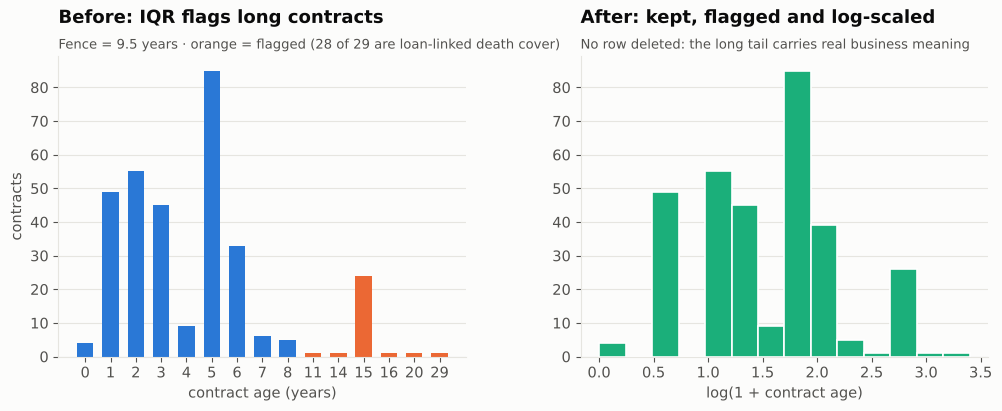

In [15]:
q1, q3 = pp["contract_age"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
pp["long_contract_flag"] = (pp["contract_age"] > fence).astype(int)
pp["contract_age_log"] = np.log1p(pp["contract_age"])
print(f"IQR upper fence = {fence:.1f} years · flagged: {pp['long_contract_flag'].sum()} contracts")
display(pp.loc[pp["long_contract_flag"] == 1].groupby("product")["contract_age"].agg(["count", "min", "max"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"wspace": 0.28})
vals = pp["contract_age"].value_counts().sort_index()
axes[0].bar(vals.index.astype(int).astype(str), vals.values,
            color=[ORANGE if v > fence else BLUE for v in vals.index], width=0.65)
axes[0].set_xlabel("contract age (years)"); axes[0].set_ylabel("contracts")
axes[0].set_title("Before: IQR flags long contracts", pad=24)
subtitle(axes[0], f"Fence = {fence:.1f} years · orange = flagged (28 of 29 are loan-linked death cover)")
axes[1].hist(pp["contract_age_log"], bins=14, color=GREEN, edgecolor="white", linewidth=1.2)
axes[1].set_xlabel("log(1 + contract age)")
axes[1].set_title("After: kept, flagged and log-scaled", pad=24)
subtitle(axes[1], "No row deleted: the long tail carries real business meaning")
for a in axes:
    a.grid(axis="x", visible=False)
save(fig, "fig12_pp_outliers")
plt.show()

### B5. Multi-valued guarantees → multi-hot, and encoded target

In [16]:
pp["guarantee_list"] = pp["guarantees"].map(split_multi)
pp["candidate_guarantee_list"] = pp["candidate_guarantees"].map(split_multi)
pp["n_guarantees"] = pp["guarantee_list"].str.len()
pp["n_candidate_products"] = pp["candidate_products"].map(split_multi).str.len()
G = sorted({g for lst in pp["guarantee_list"] for g in lst})
guar_mh = pd.DataFrame([[int(g in lst) for g in G] for lst in pp["guarantee_list"]],
                       columns=[f"gar::{g}" for g in G], index=pp.index)
pp["unpaid"] = (pp["payment_status"].map(normalize_label) == "NON PAYE").astype(int)
print(f"{len(G)} distinct guarantees · unpaid target: {pp['unpaid'].sum()} / {len(pp)}")

pp_ready = pd.concat([
    pp[["contract_id", "user_id", "product", "branch", "sub_branch", "category", "family_status", "sector",
        "profession", "contract_age", "contract_age_log", "long_contract_flag", "term_days",
        "days_to_expiry", "n_guarantees", "n_candidate_products", "unpaid"]],
    pd.get_dummies(pp[["sub_branch", "family_status"]], prefix=["sub", "fam"], dtype=int),
    guar_mh], axis=1)
log.append(audit(pp_ready, "B · contracts (model-ready)"))
pp_ready.to_csv(PROCESSED / "pp_renewals_clean.csv", index=False)
print("saved pp_renewals_clean.csv", pp_ready.shape)
pp_ready.head(3)

18 distinct guarantees · unpaid target: 12 / 320
saved pp_renewals_clean.csv (320, 45)


,contract_id,user_id,product,branch,sub_branch,category,family_status,sector,profession,contract_age,contract_age_log,long_contract_flag,term_days,days_to_expiry,n_guarantees,n_candidate_products,unpaid,sub_ASSISTANCE EN VOYAGES,sub_AUTOMOBILE,sub_DECES,...,fam_UNKNOWN,fam_VEUF(VE),gar::ASSISTANCES VOYAGES,gar::BRIS DE GLACES,gar::CATASTROPHE NATURELLE,gar::DECES,gar::DECES - I.D.T,gar::DEFENSE ET RECOURS,gar::EMEUTE ET MOUVEMENT POPULAIRE,gar::EN CAS DE VIE,gar::INCAPACITE,gar::INCENDIE,gar::INDIVIDUELLE ACCIDENT,gar::INVALIDITE PERMANENTE,gar::MALADIE,gar::P.T.A,gar::RC - RTI,gar::RESPONSABILITE CIVILE,gar::SALIM ASSISTANCE AUTOMOBILE (S2A),gar::VOL
0,2024301072579,13695,AUTOMOBILE II,AUTOMOBILE,AUTOMOBILE,UNKNOWN,MARIE,UNKNOWN,UNKNOWN,1.0,0.693147,0,364,45,2,14,1,0,1,0,...,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
1,2024301072581,13695,AUTOMOBILE II,AUTOMOBILE,AUTOMOBILE,UNKNOWN,MARIE,UNKNOWN,UNKNOWN,1.0,0.693147,0,364,45,5,14,0,0,1,0,...,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0
2,2024301026739,23616,AUTOMOBILE,AUTOMOBILE,AUTOMOBILE,PROFESSIONS & METIERS,MARIE,OUVRIERS,CONDUCTEURS DE VEHICULE ROUTIER DE TRANSPORT E...,1.0,0.693147,0,364,53,7,23,0,0,1,0,...,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,1,0,1,0


## C. Preparation summary

In [17]:
summary = pd.DataFrame(log)
summary.to_csv(ROOT / "reports" / "preparation_summary.csv", index=False)
summary

,dataset,rows,columns,missing cells,missing %
0,A · raw,1842,12,178,0.81
1,A · companies (clean),299,9,0,0.00
2,A · episodes (model-ready),440,10,0,0.00
3,B · raw,320,21,66,0.98
4,B · contracts (model-ready),320,45,0,0.00


**Status for validation 1**
- ✅ Leakage removed and an honest target built (leave-one-out episodes).
- ✅ All missing values handled (rule-based imputation + explicit `UNKNOWN`).
- ✅ Outliers analysed with a business decision for each (binarise vs keep + log).
- ✅ Encoding pipeline defined (one-hot, frequency, multi-hot) and fitted *inside* CV in notebook 04.
- ⏳ Next: text cleaning of e-mails (dataset D) and chunking of general conditions (dataset E) for the NLP/agentic DSOs; request a re-extraction of `Age` and claims, and a longer payment history for DSO2.1.